In [1]:
# Importation des bibliothèques nécessaires
import pandas as pd
import numpy as np
import glob
import os
import gc
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from multiprocessing import Pool
from sklearn.preprocessing import StandardScaler
from joblib import dump

# Création des dossiers de sortie pour les deux départements
os.makedirs("DEPT_69", exist_ok=True)
os.makedirs("DEPT_61", exist_ok=True)

In [2]:
# Étape 5.1 : Chargement de toutes les données d’un département + conversion datetime + sauvegarde initiale
def load_and_prepare_data(dept: int) -> pd.DataFrame:
    # Recherche des fichiers du département
    pattern = f"H_{dept}_*.csv.gz"
    files = sorted(glob.glob(pattern))
    if not files:
        raise FileNotFoundError(f"No files found for pattern: {pattern}")

    # Colonnes utiles
    usecols = ["NUM_POSTE", "NOM_USUEL", "AAAAMMJJHH", "T"]
    frames = []

    # Lecture et fusion de tous les fichiers correspondants
    for f in files:
        df = pd.read_csv(
            f,
            sep=";",
            compression="infer",
            encoding="latin-1",
            na_values=["mq", "MQ", "", "NaN", "-9999", "9999", "999.9"],
            usecols=usecols,
            dtype={"NUM_POSTE": "string", "AAAAMMJJHH": "string"},
            low_memory=False
        )
        df.columns = [c.strip().upper() for c in df.columns]
        frames.append(df)

    # Concaténation
    data = pd.concat(frames, ignore_index=True)

    # Conversion du champ date en datetime
    data["AAAAMMJJHH"] = pd.to_datetime(data["AAAAMMJJHH"], format="%Y%m%d%H", errors="coerce")

    # Suppression des lignes sans identifiant ou sans date valide
    data = data.dropna(subset=["NUM_POSTE", "AAAAMMJJHH"])

    # Tri temporel global (important avant séparation)
    data = data.sort_values("AAAAMMJJHH")

    # Sauvegarde initiale par station
    out_dir = f"DEPT_{dept}"
    os.makedirs(out_dir, exist_ok=True)

    saved = 0
    for sid, subset in data.groupby("NUM_POSTE"):
        path = os.path.join(out_dir, f"DEPT_{dept}_STATION_{sid}.csv")
        subset.to_csv(path, sep=';', index=False, encoding='utf-8')
        saved += 1

    print(f"Department {dept}: {len(data)} rows loaded, {saved} station files created.", flush=True)
    return data

# Appel de la fonction
dept_61_raw = load_and_prepare_data(61)
dept_69_raw = load_and_prepare_data(69)

Department 61: 3513373 rows loaded, 47 station files created.
Department 69: 3757281 rows loaded, 58 station files created.


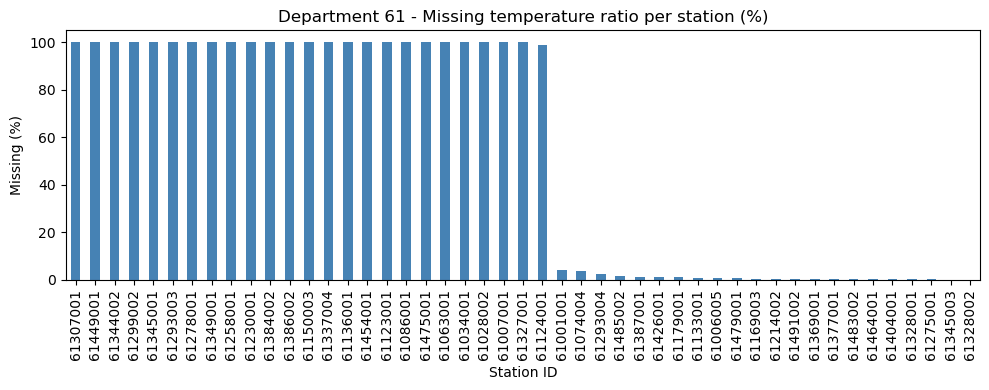

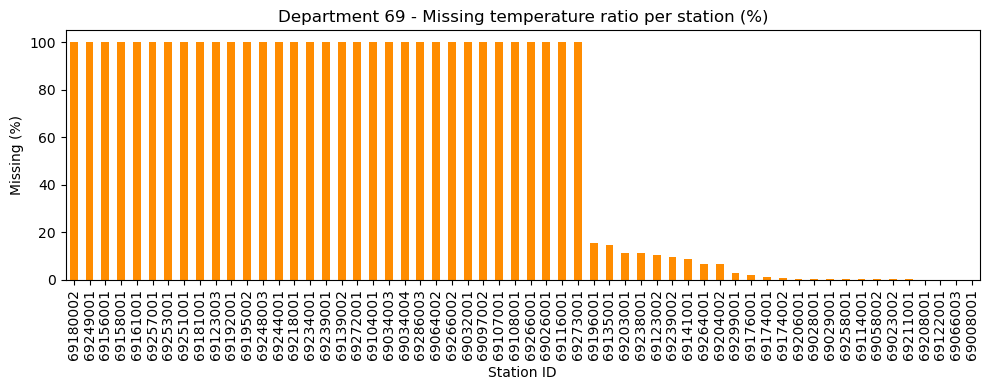

In [3]:
# Visualisation : taux de valeurs manquantes (NaN) pour chaque station

# Pour le département 61
nan_ratio_61 = (
    dept_61_raw.groupby("NUM_POSTE")["T"]
    .apply(lambda x: x.isna().mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 4))
nan_ratio_61.plot(kind="bar", color="steelblue")
plt.title("Department 61 - Missing temperature ratio per station (%)")
plt.ylabel("Missing (%)")
plt.xlabel("Station ID")
plt.tight_layout()
plt.show()

# Pour le département 69
nan_ratio_69 = (
    dept_69_raw.groupby("NUM_POSTE")["T"]
    .apply(lambda x: x.isna().mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 4))
nan_ratio_69.plot(kind="bar", color="darkorange")
plt.title("Department 69 - Missing temperature ratio per station (%)")
plt.ylabel("Missing (%)")
plt.xlabel("Station ID")
plt.tight_layout()
plt.show()

In [4]:
# Étape 5.2 : Nettoyage et reformatage + suppression des fichiers vides
def clean_existing_station_files(dept: int):
    # Dossier du département
    folder = f"DEPT_{dept}"
    files = sorted(glob.glob(f"{folder}/DEPT_{dept}_STATION_*.csv"))
    if not files:
        print(f"No station files found for department {dept}. Run Step 5.1 first.")
        return

    cleaned = 0
    deleted = 0

    for fpath in files:
        try:
            # Lecture du fichier existant
            df = pd.read_csv(fpath, sep=";", parse_dates=["AAAAMMJJHH"], dayfirst=False, encoding="utf-8")

            # Conversion de la température en valeurs numériques
            df["T"] = pd.to_numeric(df["T"], errors="coerce")

            # Suppression des lignes sans température valide ou sans identifiant
            df = df.dropna(subset=["NUM_POSTE", "AAAAMMJJHH", "T"])

            # Si le fichier devient vide après nettoyage, suppression du fichier
            if df.empty:
                os.remove(fpath)
                deleted += 1
                continue

            # Mise en index temporel et tri
            df = df.set_index("AAAAMMJJHH").sort_index()

            # Suppression des doublons d’index
            df = df[~df.index.duplicated(keep="first")]

            # Réécriture du fichier nettoyé (même nom)
            df.to_csv(fpath, sep=";", index=True, encoding="utf-8")

            cleaned += 1

        except Exception as e:
            print(f"Could not clean {os.path.basename(fpath)}: {e}")
            continue

    print(f"Department {dept}: {cleaned} station files cleaned, {deleted} empty files deleted.", flush=True)

# Appel de la fonction
clean_existing_station_files(61)
clean_existing_station_files(69)

Department 61: 23 station files cleaned, 24 empty files deleted.
Department 69: 25 station files cleaned, 33 empty files deleted.


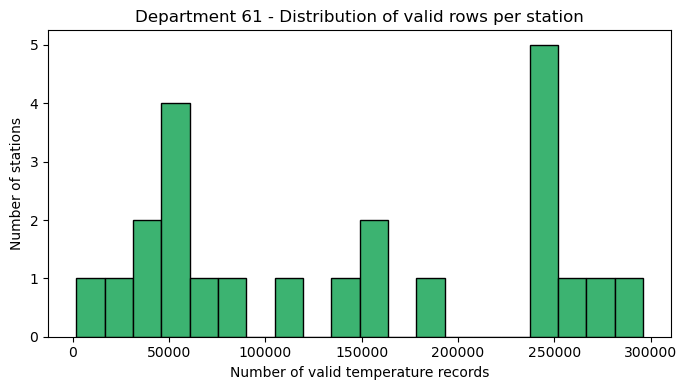

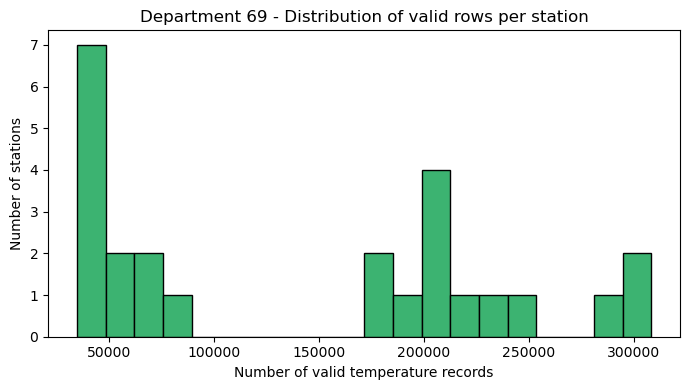

In [5]:
# Visualisation : distribution du nombre de lignes valides par station pour les départements 61 et 69
for dept in [61, 69]:
    folder = f"DEPT_{dept}"
    counts = []

    # Lecture du nombre de lignes valides pour chaque station
    for fpath in glob.glob(f"{folder}/DEPT_{dept}_STATION_*.csv"):
        df = pd.read_csv(fpath, sep=";", encoding="utf-8")
        counts.append(len(df))

    # Si aucun fichier, avertissement
    if not counts:
        print(f"No station files found for department {dept}.")
        continue

    # Création de l'histogramme
    plt.figure(figsize=(7, 4))
    plt.hist(counts, bins=20, color="mediumseagreen", edgecolor="black")
    plt.title(f"Department {dept} - Distribution of valid rows per station")
    plt.xlabel("Number of valid temperature records")
    plt.ylabel("Number of stations")
    plt.tight_layout()
    plt.show()

In [6]:
# Étape 5.3 : Reindexation horaire
def reindex_hourly_station_files(dept: int):
    # Dossier du département
    folder = f"DEPT_{dept}"
    files = sorted(glob.glob(f"{folder}/DEPT_{dept}_STATION_*.csv"))
    
    # Vérifie la présence des fichiers nettoyés
    if not files:
        print(f"No cleaned files found for department {dept}. Run Step 5.2 first.")
        return

    updated = 0
    skipped = 0

    for fpath in files:
        try:
            # Lecture du fichier existant avec index temporel
            df = pd.read_csv(
                fpath,
                sep=";",
                parse_dates=["AAAAMMJJHH"],
                index_col="AAAAMMJJHH",
                encoding="utf-8"
            )

            # Vérifie si la série est valide (non vide et étendue temporelle suffisante)
            if df.empty or df.index.min() == df.index.max():
                skipped += 1
                continue

            # Génère un index complet à fréquence horaire entre les dates min et max
            idx_full = pd.date_range(df.index.min(), df.index.max(), freq="1H")

            # Réindexe le DataFrame sur cette base (les heures manquantes deviennent NaN)
            df = df.reindex(idx_full)

            # Sauvegarde du fichier mis à jour (avec NaN conservés)
            df.index.name = "AAAAMMJJHH"
            df.to_csv(fpath, sep=";", index=True, encoding="utf-8")

            updated += 1

        except Exception as e:
            # Capture et affichage d'une erreur pour ce fichier
            print(f"{os.path.basename(fpath)}: {e}")
            continue

    # Résumé des opérations effectuées
    print(f"Department {dept}: {updated} stations reindexed hourly, {skipped} skipped")

# Appel de la fonction
reindex_hourly_station_files(61)
reindex_hourly_station_files(69)

Department 61: 23 stations reindexed hourly, 0 skipped
Department 69: 25 stations reindexed hourly, 0 skipped


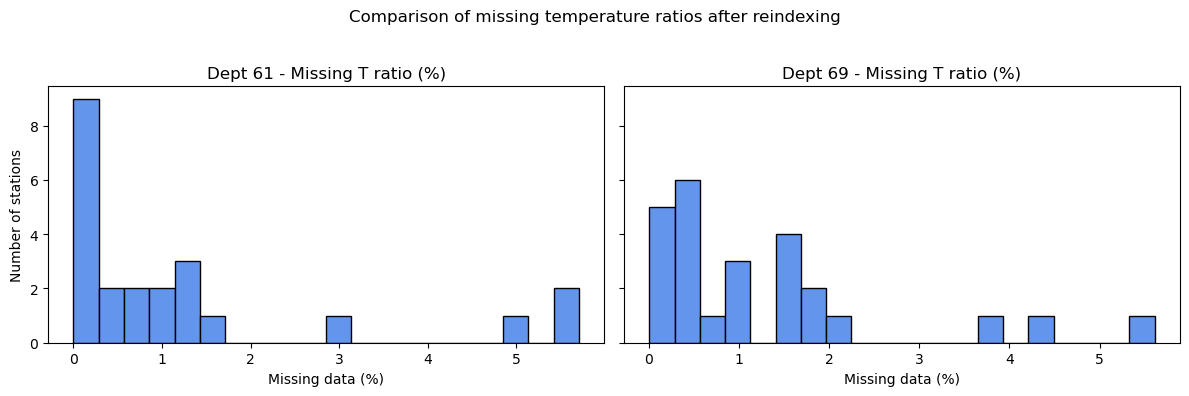

In [7]:
# Visualisation comparative des taux de valeurs manquantes après la réindexation horaire
def compare_nan_ratios_after_reindex():
    # Liste des départements à analyser
    depts = [61, 69]

    # Création d'une figure avec deux sous-graphiques côte à côte
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

    for i, dept in enumerate(depts):
        # Dossier correspondant au département
        folder = f"DEPT_{dept}"
        nan_ratios = []

        # Parcours de tous les fichiers de station du département
        for fpath in glob.glob(f"{folder}/DEPT_{dept}_STATION_*.csv"):
            # Lecture du fichier avec index temporel
            df = pd.read_csv(
                fpath,
                sep=";",
                parse_dates=["AAAAMMJJHH"],
                index_col="AAAAMMJJHH",
                encoding="utf-8"
            )

            # Calcul du pourcentage de valeurs manquantes pour la température
            if "T" in df.columns:
                nan_ratio = df["T"].isna().mean() * 100
                nan_ratios.append(nan_ratio)

        # Tracé de l'histogramme pour le département courant
        axes[i].hist(nan_ratios, bins=20, color="cornflowerblue", edgecolor="black")
        axes[i].set_title(f"Dept {dept} - Missing T ratio (%)")
        axes[i].set_xlabel("Missing data (%)")
        if i == 0:
            axes[i].set_ylabel("Number of stations")

    # Titre global et ajustement de la mise en page
    plt.suptitle("Comparison of missing temperature ratios after reindexing", fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

# Appel de la fonction
compare_nan_ratios_after_reindex()

In [8]:
# Étape 5.4 : Interpolation temporelle
def interpolate_station_files(dept: int):
    # Dossier du département
    folder = f"DEPT_{dept}"
    files = sorted(glob.glob(f"{folder}/DEPT_{dept}_STATION_*.csv"))
    
    # Vérifie la présence des fichiers réindexés
    if not files:
        print(f"No reindexed files found for department {dept}. Run Step 5.3 first.")
        return

    interpolated = 0
    failed = 0

    for fpath in files:
        try:
            # Lecture du fichier existant
            df = pd.read_csv(
                fpath,
                sep=";",
                parse_dates=["AAAAMMJJHH"],
                index_col="AAAAMMJJHH",
                encoding="utf-8"
            )

            # Ignore les fichiers vides
            if df.empty:
                continue

            # Remplit les métadonnées manquantes (identifiant et nom de station)
            for col in ["NUM_POSTE", "NOM_USUEL"]:
                if col in df.columns:
                    df[col] = df[col].ffill().bfill()

            # Interpolation linéaire dans le temps pour la température
            if "T" in df.columns:
                df["T"] = pd.to_numeric(df["T"], errors="coerce")
                df["T"] = df["T"].interpolate(method="time").ffill().bfill()
                df["T"] = df["T"].round(1)

            # Sauvegarde du fichier interpolé
            df.to_csv(fpath, sep=";", index=True, encoding="utf-8")

            interpolated += 1

        except Exception as e:
            # Affiche une erreur si un fichier échoue
            print(f"{os.path.basename(fpath)}: {e}")
            failed += 1
            continue

    # Résumé des résultats du traitement
    print(f"Department {dept}: {interpolated} station files interpolated successfully. {failed} failed.")

# Appel de la fonction
interpolate_station_files(61)
interpolate_station_files(69)

Department 61: 23 station files interpolated successfully. 0 failed.
Department 69: 25 station files interpolated successfully. 0 failed.


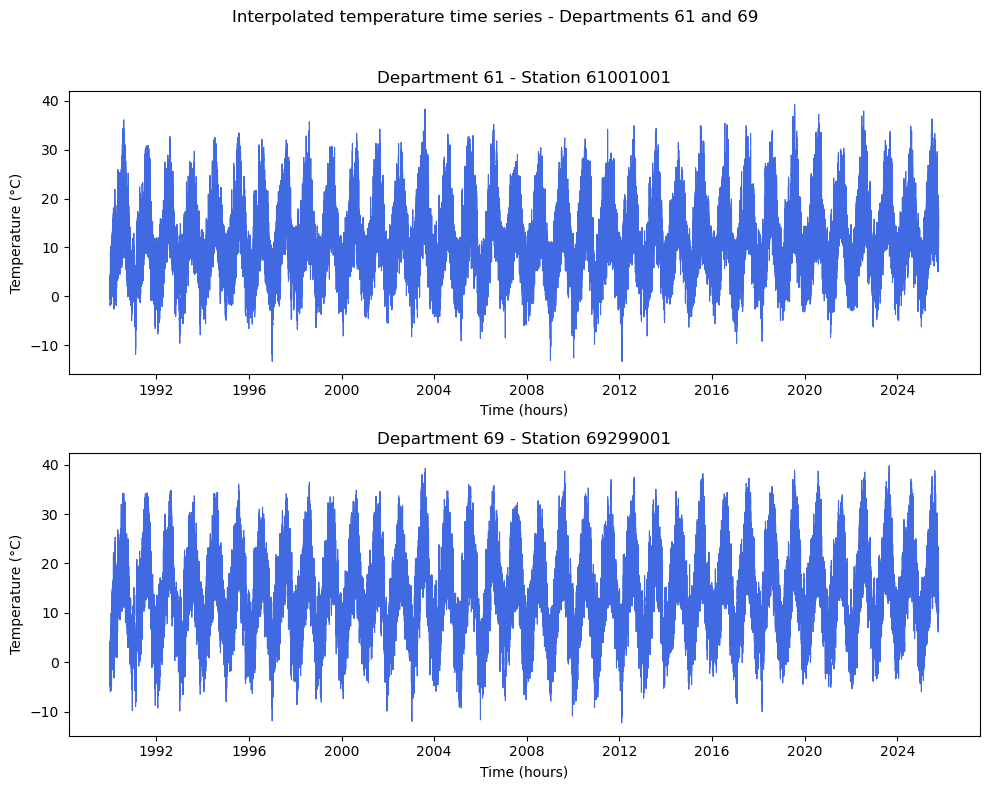

In [9]:
# Visualisation : séries temporelles après interpolation pour les deux départements

def plot_example_station_after_interpolation(ax, dept: int, station_id: str):
    # Chemin vers le fichier de la station
    path = f"DEPT_{dept}/DEPT_{dept}_STATION_{station_id}.csv"

    # Lecture des données interpolées
    df = pd.read_csv(
        path,
        sep=";",
        parse_dates=["AAAAMMJJHH"],
        index_col="AAAAMMJJHH",
        encoding="utf-8"
    )

    # Vérification de la présence de la colonne température
    if "T" not in df.columns:
        print(f"The column 'T' is missing in {station_id}.")
        return

    # Tracé sur l'axe spécifié
    ax.plot(df.index, df["T"], color="royalblue", linewidth=0.8)
    ax.set_title(f"Department {dept} - Station {station_id}")
    ax.set_xlabel("Time (hours)")
    ax.set_ylabel("Temperature (°C)")

# Création de la figure avec deux sous-graphiques (un pour chaque département)
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=False)

# Tracés pour chaque station
plot_example_station_after_interpolation(axes[0], 61, "61001001")
plot_example_station_after_interpolation(axes[1], 69, "69299001")

# Ajustement de la mise en page
fig.suptitle("Interpolated temperature time series - Departments 61 and 69", fontsize=12)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [10]:
# Étape 5.5 : Contrôle final + suppression des NaN restants + sauvegarde propre
def finalize_station_files(dept: int):
    # Dossier du département
    folder = f"DEPT_{dept}"
    files = sorted(glob.glob(f"{folder}/DEPT_{dept}_STATION_*.csv"))
    if not files:
        print(f"No interpolated files found for department {dept}. Run Step 5.4 first.")
        return

    finalized = 0
    deleted = 0

    for fpath in files:
        try:
            # Lecture du fichier existant
            df = pd.read_csv(
                fpath,
                sep=";",
                parse_dates=["AAAAMMJJHH"],
                index_col="AAAAMMJJHH",
                encoding="utf-8"
            )

            # Vérification de l'existence de la colonne T
            if "T" not in df.columns:
                print(f"Column 'T' missing in {os.path.basename(fpath)} – skipped.")
                deleted += 1
                continue

            # Suppression des fichiers contenant encore des valeurs manquantes
            if df["T"].isna().sum() > 0:
                if os.path.exists(fpath):
                    os.remove(fpath)
                deleted += 1
                continue

            # Arrondi des valeurs et suppression des doublons d'index
            df = df.round(1)
            df = df[~df.index.duplicated(keep="first")]

            # Sauvegarde du fichier final
            df.to_csv(fpath, sep=";", index=True, encoding="utf-8")
            finalized += 1

        except Exception as e:
            print(f"{os.path.basename(fpath)}: {e}")
            continue

    # Résumé des opérations effectuées
    print(f"Department {dept}: {finalized} finalized, {deleted} deleted.")

# Appel de la fonction 
finalize_station_files(61)
finalize_station_files(69)

Department 61: 23 finalized, 0 deleted.
Department 69: 25 finalized, 0 deleted.


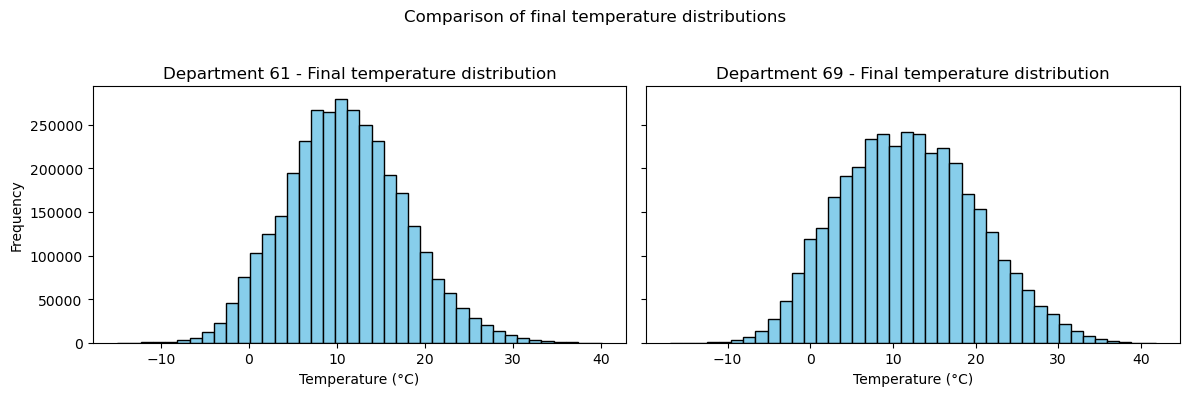

In [11]:
# Visualisation : comparaison de la distribution finale des températures après nettoyage

# Liste des départements à comparer
depts = [61, 69]

# Création d'une figure avec deux sous-graphiques côte à côte
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for i, dept in enumerate(depts):
    # Dossier du département
    folder = f"DEPT_{dept}"
    temps = []

    # Lecture de toutes les stations du département
    for fpath in glob.glob(f"{folder}/DEPT_{dept}_STATION_*.csv"):
        df = pd.read_csv(fpath, sep=";", encoding="utf-8")
        if "T" in df.columns:
            temps.extend(df["T"].dropna().values)

    # Création de l’histogramme pour ce département
    axes[i].hist(temps, bins=40, color="skyblue", edgecolor="black")
    axes[i].set_title(f"Department {dept} - Final temperature distribution")
    axes[i].set_xlabel("Temperature (°C)")
    if i == 0:
        axes[i].set_ylabel("Frequency")

# Titre global et ajustement de la mise en page
plt.suptitle("Comparison of final temperature distributions", fontsize=12)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [14]:
# Étape 5.6.1 : Décomposition STL (T -> T_T + S + R)
def stl_decompose(dept: int, period: int = 24, decimals: int = 1):
    # Applique une décomposition STL sur la température T pour chaque station.
    # Ajoute les colonnes T_T (trend), S (seasonal) et R (residual).
    folder = f"DEPT_{dept}"
    files = sorted(glob.glob(f"{folder}/DEPT_{dept}_STATION_*.csv"))
    if not files:
        print(f"No finalized files found for department {dept}. Run Étape 5.5 first.")
        return

    processed = 0
    short_series = 0
    constant_series = 0
    failed = 0

    for fpath in files:
        try:
            # Lecture
            df = pd.read_csv(
                fpath,
                sep=";",
                parse_dates=["AAAAMMJJHH"],
                index_col="AAAAMMJJHH",
                encoding="utf-8"
            )

            # Vérification basique
            if len(df) < (2 * period + 1):
                # Trop court pour STL
                df["T_T"] = df["T"]
                df["S"] = 0.0
                df["R"] = 0.0
                df.to_csv(fpath, sep=";", encoding="utf-8")
                short_series += 1
                continue

            # Conversion de T en numérique
            df["T"] = pd.to_numeric(df["T"], errors="coerce")
            if df["T"].nunique(dropna=True) <= 1:
                df["T_T"] = df["T"]
                df["S"] = 0.0
                df["R"] = 0.0
                df.to_csv(fpath, sep=";", encoding="utf-8")
                constant_series += 1
                continue

            # Application STL
            stl = STL(df["T"], period=period, robust=True)
            result = stl.fit()

            # Ajout des composantes
            df["T_T"] = result.trend.round(decimals)
            df["S"] = result.seasonal.round(decimals)
            df["R"] = result.resid.round(decimals)

            # Sauvegarde mise à jour
            df.to_csv(fpath, sep=";", encoding="utf-8")

            processed += 1

        except Exception as e:
            print(f"{os.path.basename(fpath)}: {e}")
            failed += 1
            continue
            
    print(
        f"Department {dept}: {processed} STL decompositions done, "
        f"{short_series} too short, {constant_series} constant, {failed} failed."
    )

# Appel de la fonction
stl_decompose(61, period=24)
stl_decompose(69, period=24)

Department 61: 23 STL decompositions done, 0 too short, 0 constant, 0 failed.
Department 69: 25 STL decompositions done, 0 too short, 0 constant, 0 failed.


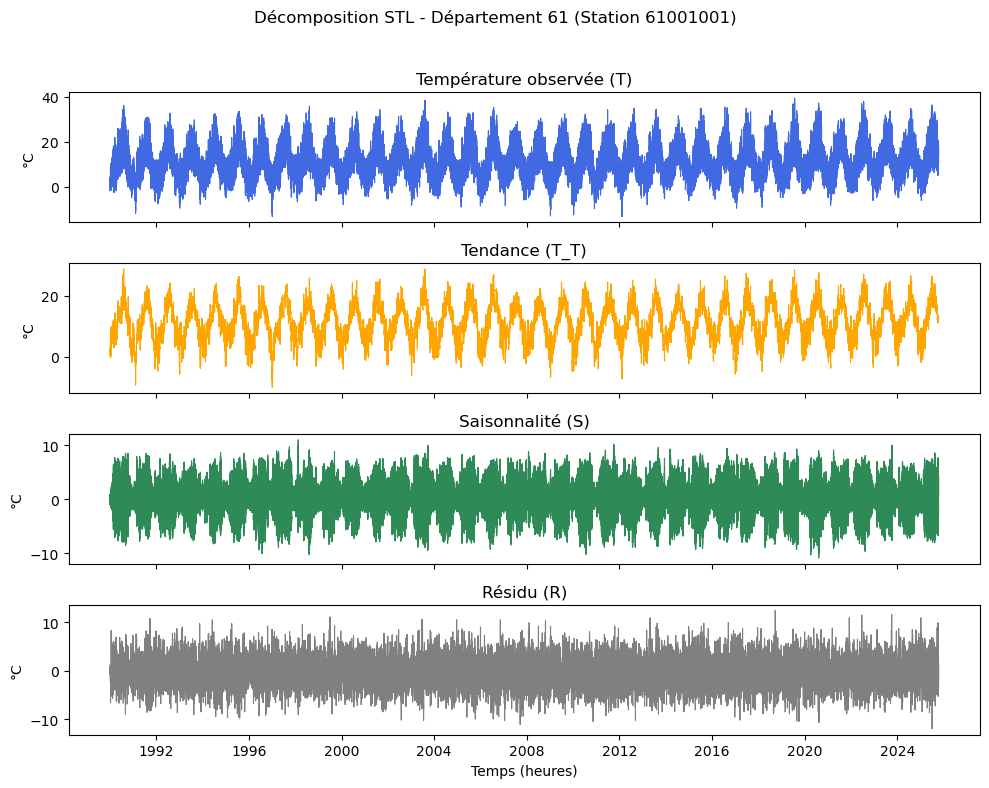

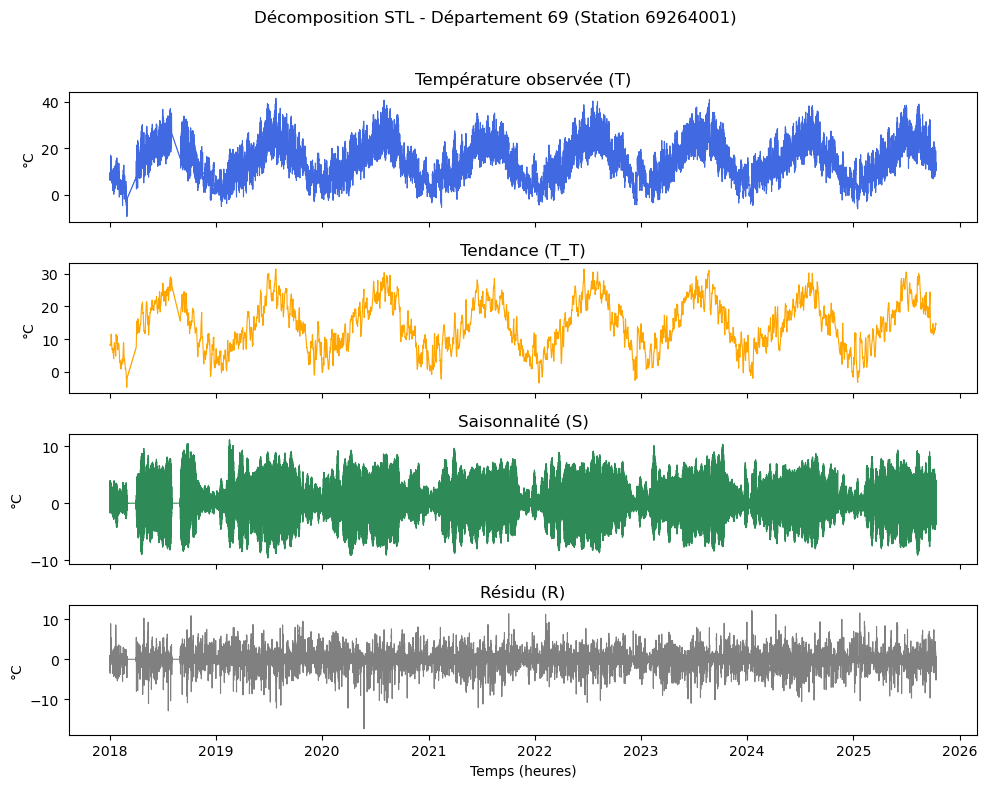

In [20]:
# Visualisation des décompositions STL pour deux départements

def plot_stl_decomposition_separate(dept: int, station_id: str):
    # Affiche la décomposition STL complète (T, T_T, S, R)
    # pour une station donnée d’un département, sur toute la période disponible.
    
    # Chargement des données
    path = f"DEPT_{dept}/DEPT_{dept}_STATION_{station_id}.csv"
    df = pd.read_csv(path, sep=";", parse_dates=["AAAAMMJJHH"],
                     index_col="AAAAMMJJHH", encoding="utf-8")

    # Vérification des colonnes nécessaires
    if not {"T", "T_T", "S", "R"}.issubset(df.columns):
        print(f"Missing STL columns for station {station_id} (department {dept}).")
        return

    # Définition des composantes et des styles
    composantes = ["T", "T_T", "S", "R"]
    titles = ["Observed Temperature (T)", "Trend (T_T)", "Seasonal (S)", "Residual (R)"]
    couleurs = ["royalblue", "orange", "seagreen", "gray"]

    # Création de la figure avec 4 sous-graphiques
    fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)

    # Tracé de chaque composante
    for ax, comp, titre, couleur in zip(axes, composantes, titres, couleurs):
        ax.plot(df.index, df[comp], color=couleur, linewidth=0.8)
        ax.set_title(titre)
        ax.set_ylabel("°C")

    # Étiquettes et mise en forme
    axes[-1].set_xlabel("Temps (heures)")
    fig.suptitle(f"Décomposition STL - Département {dept} (Station {station_id})", fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

# Affichage pour les deux départements
plot_stl_decomposition_separate(61, "61001001")
plot_stl_decomposition_separate(69, "69264001")

In [21]:
# Étape 5.6.2 : Standardisation (Z-score) + sauvegarde du scaler
def standardize_all_stations(dept: int):
    # Calcule le Z-score (standardisation) de la température T pour chaque station.
    # Sauvegarde les scalers individuels au format joblib.
    
    # Dossier du département
    folder = f"DEPT_{dept}"
    files = sorted(glob.glob(f"{folder}/DEPT_{dept}_STATION_*.csv"))
    if not files:
        print(f"No station files found for department {dept}. Run Step 5.6.1 first.")
        return

    # Création d’un sous-dossier pour les scalers
    scaler_dir = os.path.join(folder, "scalers")
    os.makedirs(scaler_dir, exist_ok=True)

    standardized = 0
    skipped = 0
    failed = 0

    for i, fpath in enumerate(files, start=1):
        try:
            # Lecture du fichier CSV
            df = pd.read_csv(fpath, sep=";", parse_dates=["AAAAMMJJHH"],
                             index_col="AAAAMMJJHH", encoding="utf-8")

            # Vérifie la présence et la validité de la colonne T
            if "T" not in df.columns or df["T"].isna().all():
                skipped += 1
                continue

            # Remplacement des valeurs infinies et comblement des NaN
            t_values = df[["T"]].replace([np.inf, -np.inf], np.nan).ffill().bfill()

            # Application du StandardScaler (Z-score)
            scaler = StandardScaler()
            df["T_Z"] = np.round(scaler.fit_transform(t_values), 3)  

            # Sauvegarde du scaler individuel
            scaler_name = os.path.basename(fpath).replace(".csv", "_SCALER.joblib")
            scaler_path = os.path.join(scaler_dir, scaler_name)
            dump(scaler, scaler_path)

            # Sauvegarde du fichier mis à jour
            df.to_csv(fpath, sep=";", encoding="utf-8")

            standardized += 1

        except Exception as e:
            failed += 1
            print(f"{os.path.basename(fpath)}: {e}")
            continue

    print(f"Dept {dept}: {standardized} standardized, {skipped} skipped (no data), {failed} failed.")

# Appel de la fonction
standardize_all_stations(61)
standardize_all_stations(69)

Dept 61: 23 standardized, 0 skipped (no data), 0 failed.
Dept 69: 25 standardized, 0 skipped (no data), 0 failed.


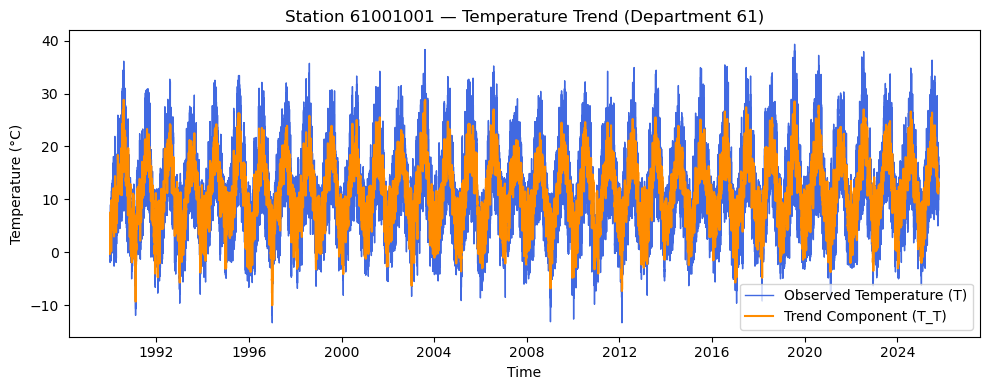

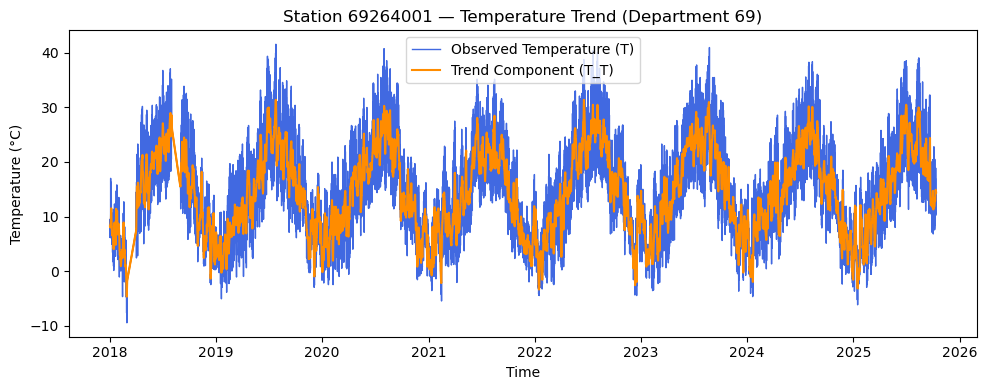

In [22]:
# Visualisation de la tendance (T vs T_T) ---
def plot_trend_component(dept: int, station_id: str):
    # Chargement du fichier de la station
    path = f"DEPT_{dept}/DEPT_{dept}_STATION_{station_id}.csv"
    df = pd.read_csv(path, sep=";", parse_dates=["AAAAMMJJHH"], index_col="AAAAMMJJHH", encoding="utf-8")

    # Tracé de la température observée et de la tendance
    plt.figure(figsize=(10, 4))
    plt.plot(df.index, df["T"], label="Observed Temperature (T)", linewidth=1, color="royalblue")
    plt.plot(df.index, df["T_T"], label="Trend Component (T_T)", linewidth=1.5, color="darkorange")
    plt.title(f"Station {station_id} — Temperature Trend (Department {dept})")
    plt.xlabel("Time")
    plt.ylabel("Temperature (°C)")
    plt.legend()
    plt.tight_layout()
    plt.show()

# Exemple
plot_trend_component(61, "61001001")
plot_trend_component(69, "69264001")

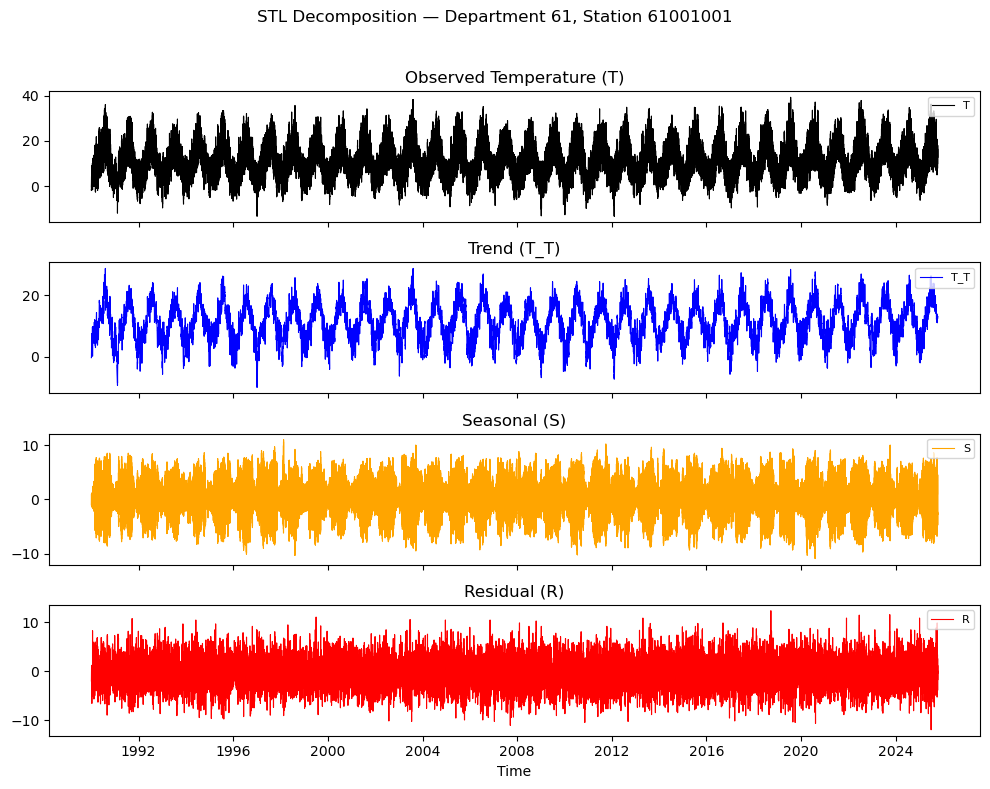

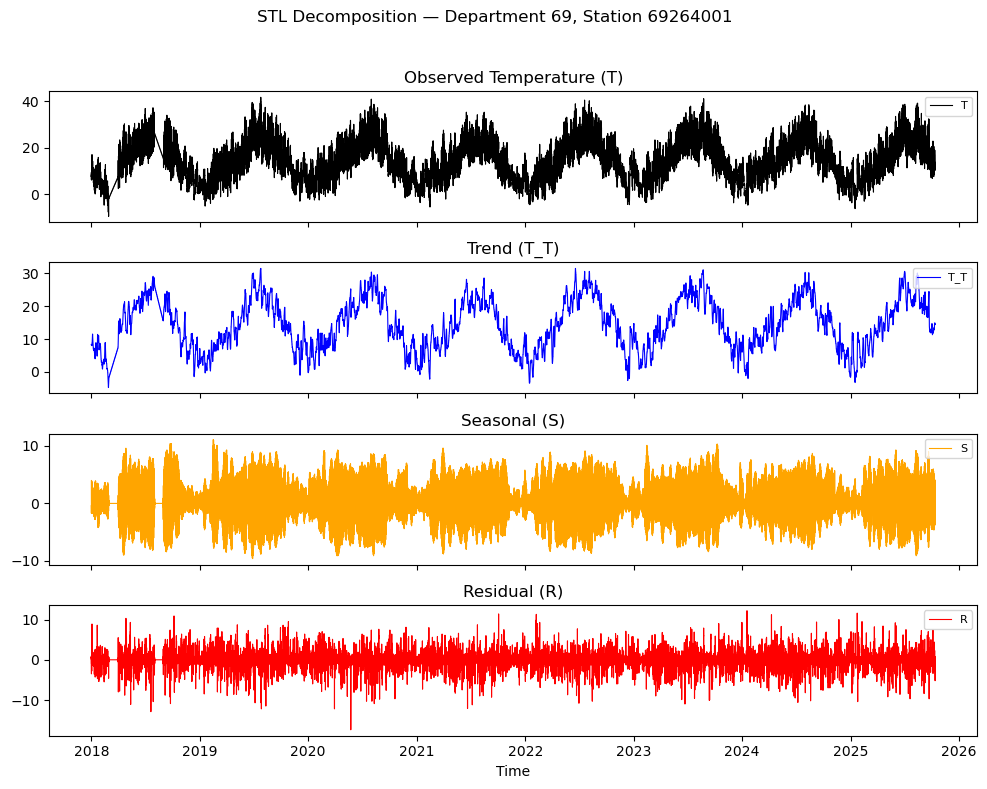

In [23]:
# Décomposition STL complète
def plot_stl_full(dept: int, station_id: str):
    # Chargement du fichier de la station
    path = f"DEPT_{dept}/DEPT_{dept}_STATION_{station_id}.csv"
    df = pd.read_csv(path, sep=";", parse_dates=["AAAAMMJJHH"],
                     index_col="AAAAMMJJHH", encoding="utf-8")

    # Vérification des colonnes nécessaires
    if not {"T", "T_T", "S", "R"}.issubset(df.columns):
        print(f"Missing STL columns for station {station_id} (Department {dept}).")
        return

    # Tracé des composantes STL (observed, trend, seasonal, residual)
    fig, axs = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
    components = [
        ("T", "Observed Temperature (T)", "black"),
        ("T_T", "Trend (T_T)", "blue"),
        ("S", "Seasonal (S)", "orange"),
        ("R", "Residual (R)", "red"),
    ]
    for ax, (col, title, color) in zip(axs, components):
        ax.plot(df.index, df[col], color=color, linewidth=0.8)
        ax.set_title(title)
        ax.legend([col], loc="upper right", fontsize=8)
    axs[-1].set_xlabel("Time")
    plt.suptitle(f"STL Decomposition — Department {dept}, Station {station_id}", fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

# Exemple
plot_stl_full(61, "61001001")
plot_stl_full(69, "69264001")

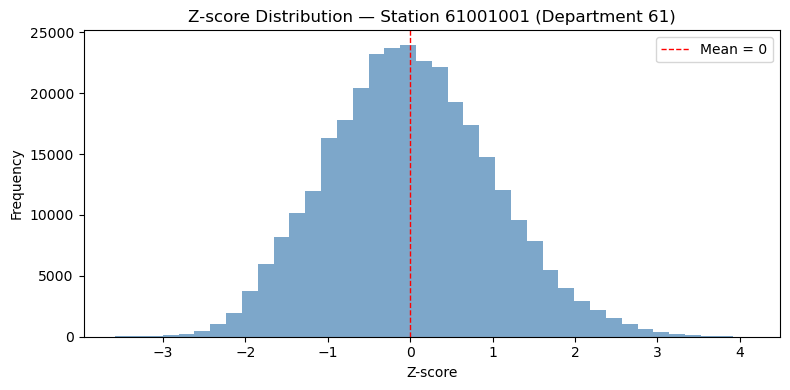

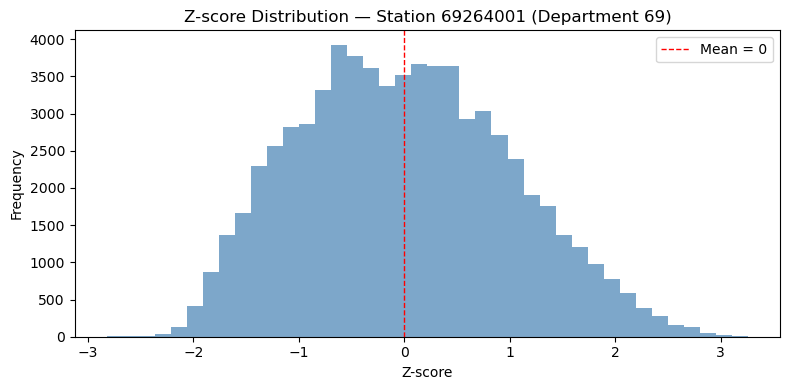

In [24]:
# Distribution normalisée (Z-score)
def plot_zscore_distribution(dept: int, station_id: str):
    # Chargement du fichier de la station
    path = f"DEPT_{dept}/DEPT_{dept}_STATION_{station_id}.csv"
    df = pd.read_csv(path, sep=";", parse_dates=["AAAAMMJJHH"],
                     index_col="AAAAMMJJHH", encoding="utf-8")

    # Vérification de la présence de la colonne T_Z
    if "T_Z" not in df.columns:
        print(f"No 'T_Z' column found for station {station_id} (Department {dept}).")
        return

    # Tracé de la distribution des Z-scores
    plt.figure(figsize=(8, 4))
    plt.hist(df["T_Z"].dropna(), bins=40, color="steelblue", alpha=0.7)
    plt.axvline(0, color="red", linestyle="--", linewidth=1, label="Mean = 0")
    plt.title(f"Z-score Distribution — Station {station_id} (Department {dept})")
    plt.xlabel("Z-score")
    plt.ylabel("Frequency")
    plt.legend()
    plt.tight_layout()
    plt.show()

# Exemple
plot_zscore_distribution(61, "61001001")
plot_zscore_distribution(69, "69264001")

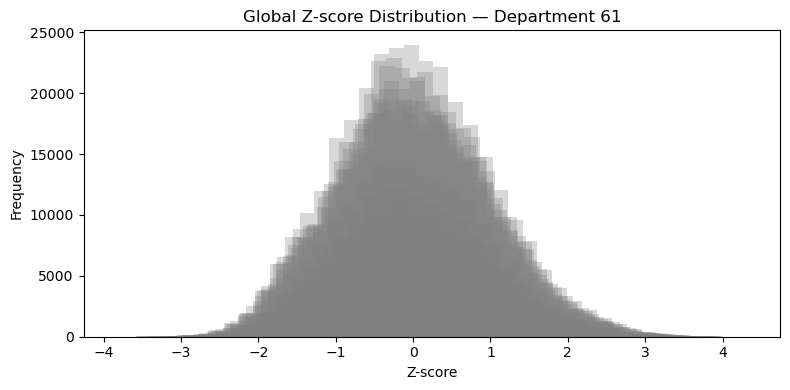

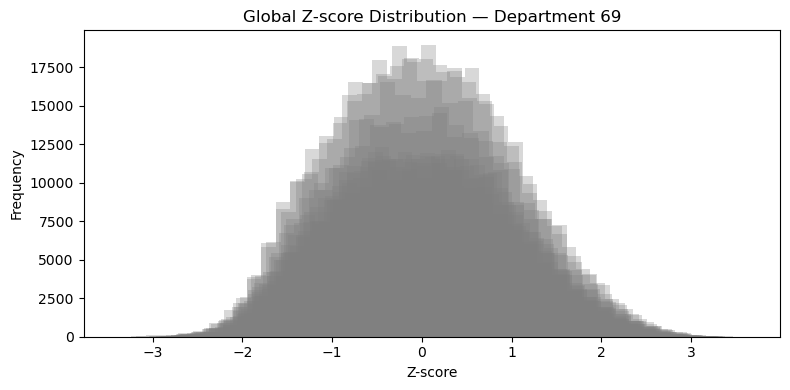

In [25]:
# Répartition globale des Z-scores
def plot_global_zscore_distribution(dept: int):
    # Lecture de tous les fichiers de stations du département
    folder = f"DEPT_{dept}"
    files = sorted(glob.glob(f"{folder}/DEPT_{dept}_STATION_*.csv"))

    # Tracé superposé des distributions pour toutes les stations
    plt.figure(figsize=(8, 4))
    for fpath in files:
        try:
            df = pd.read_csv(fpath, sep=";", encoding="utf-8")
            if "T_Z" in df.columns:
                plt.hist(df["T_Z"].dropna(), bins=40, alpha=0.3, color="gray")
        except Exception:
            continue
    plt.title(f"Global Z-score Distribution — Department {dept}")
    plt.xlabel("Z-score")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

# Exemple
plot_global_zscore_distribution(61)
plot_global_zscore_distribution(69)

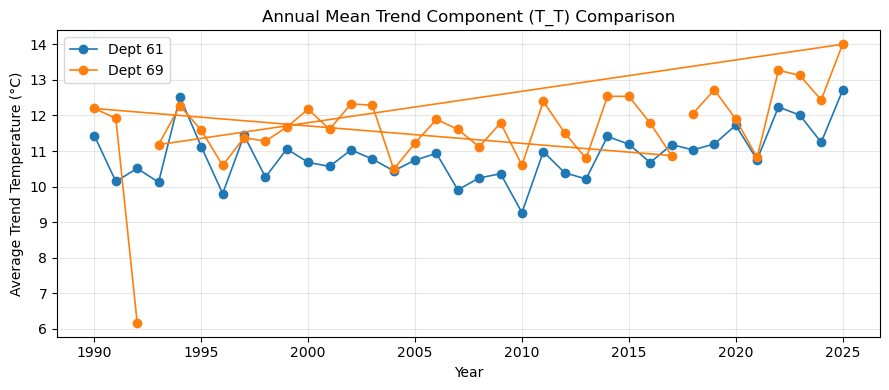

In [28]:
# Évolution annuelle des tendances (T_T)
def plot_annual_trend_comparison():
    # Compare l'évolution annuelle de la composante de tendance (T_T) entre les départements 61 et 69.
    depts = [61, 69]
    means = {}

    for dept in depts:
        folder = f"DEPT_{dept}"
        files = sorted(glob.glob(f"{folder}/DEPT_{dept}_STATION_*.csv"))
        all_data = []

        for fpath in files:
            try:
                df = pd.read_csv(fpath, sep=";", parse_dates=["AAAAMMJJHH"], 
                                 index_col="AAAAMMJJHH", encoding="utf-8")
                if "T_T" in df.columns:
                    df["Year"] = df.index.year
                    yearly_mean = df.groupby("Year")["T_T"].mean()
                    all_data.append(yearly_mean)
            except Exception:
                continue

        if all_data:
            means[dept] = pd.concat(all_data, axis=1).mean(axis=1)

    # --- Tracé comparatif ---
    plt.figure(figsize=(9, 4))
    for dept, series in means.items():
        plt.plot(series.index, series.values, marker="o", linewidth=1.2, label=f"Dept {dept}")
    plt.title("Annual Mean Trend Component (T_T) Comparison")
    plt.xlabel("Year")
    plt.ylabel("Average Trend Temperature (°C)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# Exemple
plot_annual_trend_comparison()

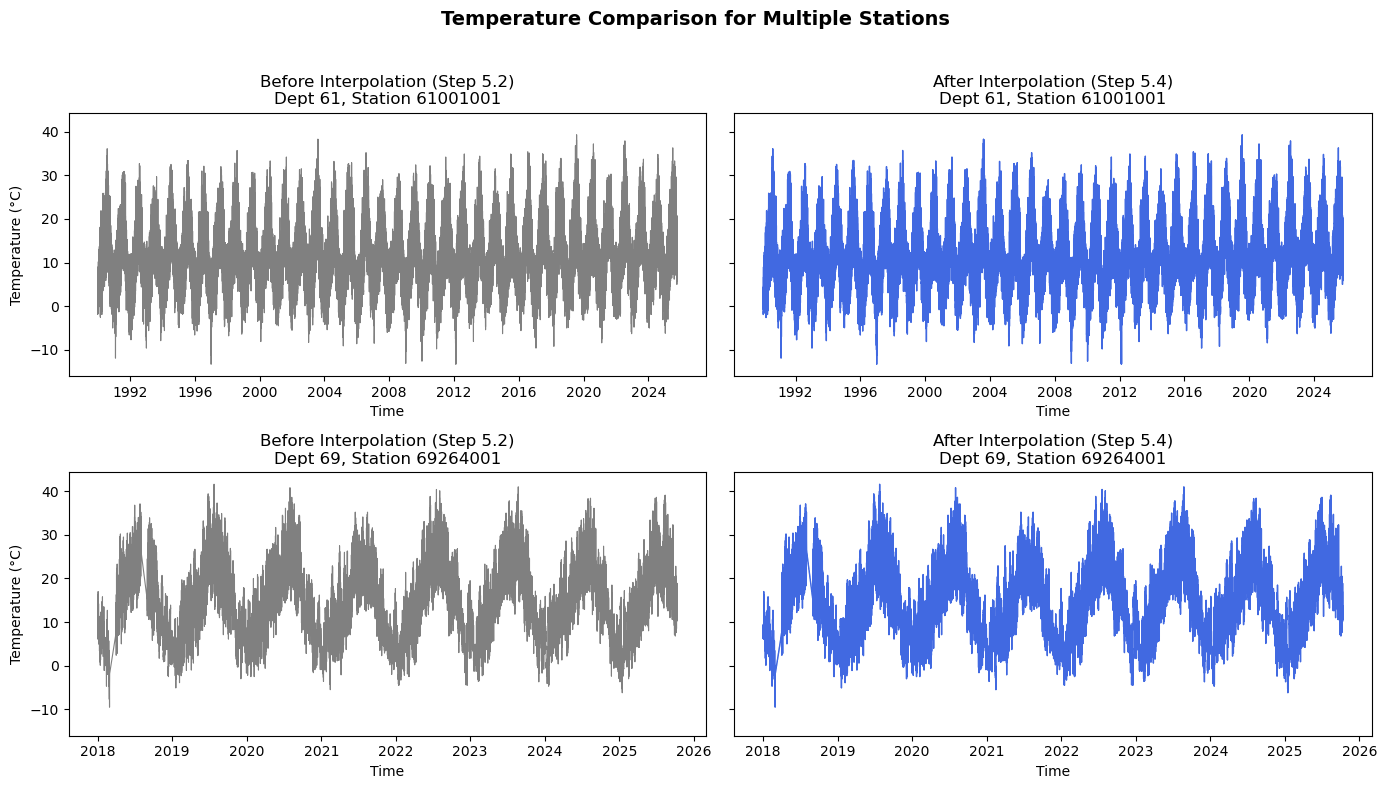

In [40]:
def compare_multiple_stations(dept_station_list):
    # Compare la température avant (Étape 5.2) et après interpolation (Étape 5.4)
    # pour plusieurs stations, dans une seule figure organisée en sous-graphiques.

    # Nombre total de stations
    n = len(dept_station_list)
    fig, axes = plt.subplots(n, 2, figsize=(14, 4 * n), sharey=True)

    # Si une seule station est fournie, convertir en liste de listes
    if n == 1:
        axes = [axes]

    for i, (dept, station_id) in enumerate(dept_station_list):
        # Définition des chemins
        path_before = f"Etape 5.2/DEPT_{dept}/DEPT_{dept}_STATION_{station_id}.csv"
        path_after = f"Etape 5.4/DEPT_{dept}/DEPT_{dept}_STATION_{station_id}.csv"

        # Vérification de l'existence des fichiers
        if not os.path.exists(path_before) or not os.path.exists(path_after):
            print(f"Missing files for station {station_id} (Dept {dept}).")
            continue

        # Lecture des données
        df_before = pd.read_csv(path_before, sep=";", parse_dates=["AAAAMMJJHH"],
                                index_col="AAAAMMJJHH", encoding="utf-8")
        df_after = pd.read_csv(path_after, sep=";", parse_dates=["AAAAMMJJHH"],
                               index_col="AAAAMMJJHH", encoding="utf-8")

        # Vérifie la colonne de température
        if "T" not in df_before.columns or "T" not in df_after.columns:
            print(f"Missing column 'T' for station {station_id}.")
            continue

        # Graphique avant interpolation
        axes[i][0].plot(df_before.index, df_before["T"], color="gray", linewidth=0.8)
        axes[i][0].set_title(f"Before Interpolation (Step 5.2)\nDept {dept}, Station {station_id}")
        axes[i][0].set_xlabel("Time")
        axes[i][0].set_ylabel("Temperature (°C)")

        # Graphique après interpolation
        axes[i][1].plot(df_after.index, df_after["T"], color="royalblue", linewidth=1.0)
        axes[i][1].set_title(f"After Interpolation (Step 5.4)\nDept {dept}, Station {station_id}")
        axes[i][1].set_xlabel("Time")

    # Titre global et ajustement
    plt.suptitle("Temperature Comparison for Multiple Stations", fontsize=14, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

# Exemple
compare_multiple_stations([
    (61, "61001001"),
    (69, "69264001")
])